# Rozwiązanie: wycena laptopów — Random Forest i Gradient Boosting
**Dwa zmieniane parametry na algorytm · kompletne wyniki i interpretacja**

**Cel:** porównać modele bazowe ze zmienionymi konfiguracjami i sprawdzić, czy modyfikacje poprawiają przewidywanie cen nowych ofert.

Używamy tych samych 1200 syntetycznych ofert, tego samego podziału 60/20/20 i ziarna losowego 42 co w zadaniu. Nie są to rzeczywiste ceny rynkowe.

| Algorytm | Parametr 1 | Parametr 2 |
|---|---|---|
| Random Forest | max_depth: 8 → 16 | min_samples_leaf: 2 → 5 |
| Gradient Boosting | n_estimators: 80 → 160 | learning_rate: 0.05 → 0.10 |

Dla każdego algorytmu porównujemy cztery konfiguracje: bazę, zmianę pierwszego parametru, zmianę drugiego oraz obie zmiany razem. To **osiem modeli**, ale tylko dwa badane parametry na algorytm. Próby pośrednie pozwalają odróżnić wpływ poszczególnych zmian od ich łącznego efektu.

Wybór opieramy wyłącznie na MAE walidacyjnym. Na końcu jednorazowo pokazujemy wyniki testowe wszystkich zamrożonych konfiguracji — opisowo, bez zmiany zwycięzcy. To porównanie ustalonych ustawień, a nie dowód znalezienia globalnie optymalnych parametrów.

Wszystkie komórki zostały wykonane. Można ponownie uruchomić notebook od góry; czasy uczenia mogą się różnić.

## 1. Dane i podział
Model korzysta z marki, wydajności CPU, RAM, SSD, klasy GPU, wieku, stanu, gwarancji i kondycji baterii.

**Trening 60%** służy uczeniu; **walidacja 20%** służy wyborowi konfiguracji; **test 20%** służy końcowej ocenie. ID oferty nie jest cechą. Braki liczb uzupełniamy medianą treningu, a marki i inne kategorie kodujemy one-hot. Drzewa nie wymagają skalowania.

In [1]:
# %pip install numpy pandas matplotlib scikit-learn
import sys, time, json, copy
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import clone
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.grid': True})
SEED = 42
print('Python:', sys.version.split()[0], '| scikit-learn:', sklearn.__version__)

Python: 3.12.14 | scikit-learn: 1.8.0


In [2]:
def generuj_oferty(n=1200, seed=SEED):
    rng = np.random.default_rng(seed)
    d = pd.DataFrame({
        'id_oferty': np.arange(1, n+1),
        'marka': rng.choice(['Alfa', 'Beta', 'Gamma', 'Delta'], n),
        'cpu_punkty': rng.integers(1500, 16001, n),
        'ram_gb': rng.choice([8, 16, 32, 64], n, p=[0.25, 0.40, 0.28, 0.07]),
        'ssd_gb': rng.choice([256, 512, 1024, 2048], n, p=[0.20, 0.40, 0.32, 0.08]),
        'gpu_klasa': rng.choice(['brak', 'podstawowa', 'srednia', 'wysoka'], n, p=[0.4, 0.25, 0.25, 0.1]),
        'wiek_mies': rng.integers(3, 85, n),
        'stan': rng.choice(['dostateczny', 'dobry', 'bardzo_dobry'], n, p=[0.15, 0.5, 0.35]),
        'gwarancja_mies': rng.choice([0, 6, 12], n, p=[0.65, 0.2, 0.15])
    })
    d['bateria_proc'] = np.clip(100 - 0.5*d.wiek_mies + rng.normal(0, 8, n), 35, 100).round()
    baza = (900 + 0.22*d.cpu_punkty + 22*d.ram_gb + 0.22*d.ssd_gb
        + d.gpu_klasa.map({'brak': 0, 'podstawowa': 450, 'srednia': 1200, 'wysoka': 2300})
        + d.marka.map({'Alfa': 0, 'Beta': 180, 'Gamma': 350, 'Delta': 550}))
    cena = (baza * np.exp(-d.wiek_mies/110)
        * d.stan.map({'dostateczny': 0.76, 'dobry': 0.9, 'bardzo_dobry': 1.0})
        + 12*d.gwarancja_mies - 8*np.maximum(75-d.bateria_proc, 0)
        + 350*((d.gpu_klasa == 'wysoka') & (d.ram_gb >= 32)))
    # Szum zależy od ceny: droższe oferty mają większy rozrzut w PLN.
    d['cena_pln'] = np.maximum(250, cena + rng.normal(0, 100 + 0.06*cena, n)).round(0)
    for col in ['bateria_proc', 'ssd_gb']:
        d.loc[rng.choice(n, int(0.03*n), replace=False), col] = np.nan
    return d

dane = generuj_oferty()
X = dane.drop(columns=['cena_pln', 'id_oferty'])
y = dane['cena_pln']
# 60% trening, 20% walidacja, 20% test. Testu jeszcze nie analizujemy.
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.25, random_state=SEED)
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_dev.index).isdisjoint(X_test.index)
print('Trening / walidacja / test:', len(X_train), len(X_val), len(X_test))

Trening / walidacja / test: 720 240 240


### Przygotowanie i metryki
**MAE** to średni bezwzględny błąd ceny w PLN: niżej = lepiej. MAE=250 PLN nie gwarantuje, że każda wycena ma błąd mniejszy niż 250 PLN.

Porównujemy MAE treningu i walidacji. Bardzo niski błąd treningowy przy wysokim walidacyjnym może wskazywać przeuczenie. Baseline zawsze przewiduje medianę cen treningowych.

Dodatkowo raportujemy RMSE (większa kara za duże pomyłki), R², czas uczenia oraz lukę MAE walidacja − trening.

In [3]:
def zbuduj_pipeline(X_przyklad, estimator):
    numeric = X_przyklad.select_dtypes(include='number').columns.tolist()
    categorical = X_przyklad.select_dtypes(exclude='number').columns.tolist()
    # Zgodność ze starszymi i nowszymi wydaniami sklearn.
    try:
        encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
    except TypeError:
        encoder = OneHotEncoder(handle_unknown='ignore', sparse=False)
    prep = ColumnTransformer([
        ('num', SimpleImputer(strategy='median'), numeric),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                          ('encoder', encoder)]), categorical)
    ])
    return Pipeline([('prep', prep), ('model', clone(estimator))])

In [4]:
wyniki, modele = {}, {}
def ocen(nazwa, estimator):
    model = zbuduj_pipeline(X_train, estimator)
    start = time.perf_counter()
    model.fit(X_train, y_train)
    czas = time.perf_counter()-start
    modele[nazwa] = model
    pt, pv = model.predict(X_train), model.predict(X_val)
    mt, mv = mean_absolute_error(y_train, pt), mean_absolute_error(y_val, pv)
    wyniki[nazwa] = {'konfiguracja': nazwa, 'MAE_trening': mt, 'MAE_walidacja': mv,
        'RMSE_walidacja': np.sqrt(mean_squared_error(y_val, pv)),
        'R2_walidacja': r2_score(y_val, pv), 'luka_MAE': mv-mt, 'sekundy': czas}
    return pd.DataFrame([wyniki[nazwa]]).round(2)

def ranking():
    return pd.DataFrame(wyniki.values()).sort_values('MAE_walidacja')

baseline = DummyRegressor(strategy='median').fit(X_train, y_train)
mae_baseline = mean_absolute_error(y_val, baseline.predict(X_val))
print(f'Baseline — MAE walidacji: {mae_baseline:.2f} PLN')
display(X_train.head(3))


Baseline — MAE walidacji: 814.72 PLN


,marka,cpu_punkty,ram_gb,ssd_gb,gpu_klasa,wiek_mies,stan,gwarancja_mies,bateria_proc
1161,Beta,12397,8,512.0,podstawowa,20,dobry,12,78.0
465,Delta,7244,32,256.0,srednia,6,dobry,6,100.0
772,Alfa,11387,32,1024.0,podstawowa,30,dobry,0,83.0


## 2. Modele bazowe
Random Forest uśrednia prognozy zróżnicowanych drzew. Gradient Boosting dodaje drzewa poprawiające dotychczasowe prognozy. Zachowujemy konfiguracje bazowe z zadania.

In [5]:
RF_BAZA = dict(n_estimators=80, max_depth=8, min_samples_leaf=2, random_state=SEED, n_jobs=-1)
GB_BAZA = dict(n_estimators=80, learning_rate=0.05, max_depth=2, random_state=SEED)
display(ocen('RF_baza', RandomForestRegressor(**RF_BAZA)))
display(ocen('GB_baza', GradientBoostingRegressor(**GB_BAZA)))

,konfiguracja,MAE_trening,MAE_walidacja,RMSE_walidacja,R2_walidacja,luka_MAE,sekundy
0,RF_baza,196.47,373.66,491.42,0.78,177.19,0.13


,konfiguracja,MAE_trening,MAE_walidacja,RMSE_walidacja,R2_walidacja,luka_MAE,sekundy
0,GB_baza,353.26,416.82,552.86,0.72,63.56,0.1


## 3. Random Forest — głębokość i rozmiar liścia
**Hipoteza przed eksperymentem:** zwiększenie głębokości z 8 do 16 pozwoli odtworzyć bardziej złożone zależności, ale może zwiększyć przeuczenie. Zwiększenie minimalnej liczby ofert w liściu z 2 do 5 powinno wygładzić prognozy i ograniczyć dopasowanie do drobnych wzorców. Połączenie obu zmian nie musi dać najlepszego wyniku.

Liczba drzew pozostaje równa 80. Porównujemy każdą zmianę osobno i obie razem.

In [6]:
RF_PROBY = {
    'RF_glebokosc': {**RF_BAZA, 'max_depth': 16},
    'RF_lisc': {**RF_BAZA, 'min_samples_leaf': 5},
    'RF_obie': {**RF_BAZA, 'max_depth': 16, 'min_samples_leaf': 5}
}
for nazwa, params in RF_PROBY.items():
    ocen(nazwa, RandomForestRegressor(**params))
display(ranking()[ranking().konfiguracja.str.startswith('RF')].round(2))


,konfiguracja,MAE_trening,MAE_walidacja,RMSE_walidacja,R2_walidacja,luka_MAE,sekundy
2,RF_glebokosc,157.93,367.54,485.93,0.79,209.61,0.11
0,RF_baza,196.47,373.66,491.42,0.78,177.19,0.13
4,RF_obie,251.17,389.15,514.43,0.76,137.98,0.09
3,RF_lisc,256.83,391.47,516.39,0.76,134.64,0.09


## 4. Gradient Boosting — liczba drzew i tempo uczenia
**Hipoteza przed eksperymentem:** model bazowy z 80 drzewami i learning_rate=0.05 może być niedopasowany. Więcej drzew lub większa siła poprawki mogą zmniejszyć błąd. Obie zmiany razem dają silniejsze dopasowanie, ale istnieje ryzyko przeuczenia.

Głębokość pozostaje równa 2. Zależność między learning rate i liczbą drzew nie jest prostą równoważnością — podwojenie jednego nie musi mieć takiego samego efektu jak podwojenie drugiego.

In [7]:
GB_PROBY = {
    'GB_drzewa': {**GB_BAZA, 'n_estimators': 160},
    'GB_tempo': {**GB_BAZA, 'learning_rate': 0.10},
    'GB_obie': {**GB_BAZA, 'n_estimators': 160, 'learning_rate': 0.10}
}
for nazwa, params in GB_PROBY.items():
    ocen(nazwa, GradientBoostingRegressor(**params))
display(ranking()[ranking().konfiguracja.str.startswith('GB')].round(2))


,konfiguracja,MAE_trening,MAE_walidacja,RMSE_walidacja,R2_walidacja,luka_MAE,sekundy
7,GB_obie,204.88,299.65,399.79,0.86,94.77,0.12
6,GB_tempo,254.45,328.12,446.50,0.82,73.66,0.06
5,GB_drzewa,256.79,331.14,449.86,0.82,74.35,0.12
1,GB_baza,353.26,416.82,552.86,0.72,63.56,0.10


## 5. Porównanie i zamrożenie wyboru przed testem
Wybieramy najniższy MAE walidacyjny spośród wszystkich ośmiu ustalonych konfiguracji. Dodatnia poprawa procentowa oznacza zmniejszenie błędu względem bazy tego samego algorytmu. Oddzielnie sprawdzamy, co dało łączne zmienienie dwóch parametrów.

Nie uczymy modeli ponownie na treningu+walidacji: test ocenia dokładnie dopasowane wcześniej modele. Po obejrzeniu testu nie modyfikujemy parametrów ani wyboru.

WYBÓR ZAMROŻONY PRZED TESTEM: GB_obie


,konfiguracja,MAE_trening,MAE_walidacja,RMSE_walidacja,R2_walidacja,luka_MAE,sekundy,poprawa_vs_baza_proc
7,GB_obie,204.88,299.65,399.79,0.86,94.77,0.12,28.11
6,GB_tempo,254.45,328.12,446.50,0.82,73.66,0.06,21.28
5,GB_drzewa,256.79,331.14,449.86,0.82,74.35,0.12,20.56
2,RF_glebokosc,157.93,367.54,485.93,0.79,209.61,0.11,1.64
0,RF_baza,196.47,373.66,491.42,0.78,177.19,0.13,0.00
4,RF_obie,251.17,389.15,514.43,0.76,137.98,0.09,-4.15
3,RF_lisc,256.83,391.47,516.39,0.76,134.64,0.09,-4.77
1,GB_baza,353.26,416.82,552.86,0.72,63.56,0.10,0.00


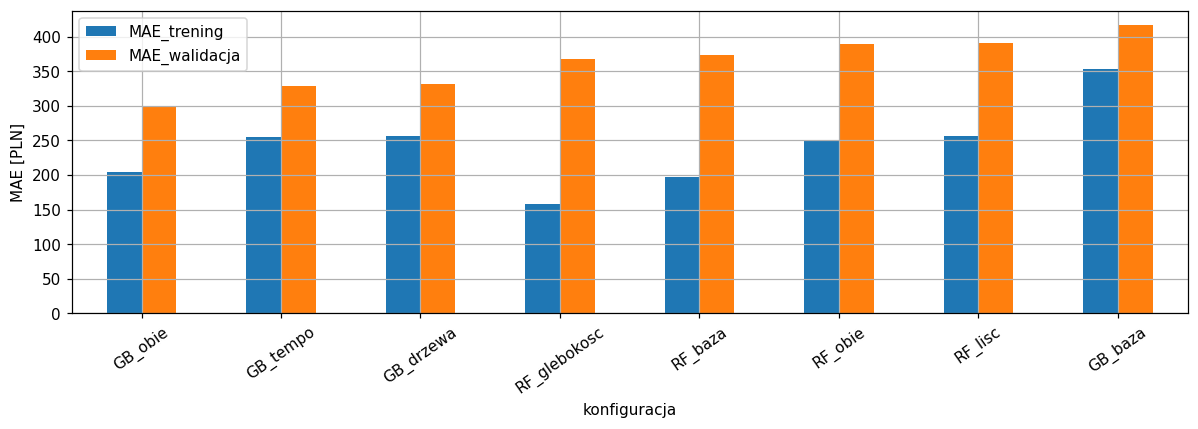

In [8]:
tabela = ranking().copy()
tabela['poprawa_vs_baza_proc'] = [
    100*(wyniki[n[:2]+'_baza']['MAE_walidacja']-wyniki[n]['MAE_walidacja'])
    / wyniki[n[:2]+'_baza']['MAE_walidacja'] for n in tabela.konfiguracja]
display(tabela.round(2))
tabela.set_index('konfiguracja')[['MAE_trening','MAE_walidacja']].plot.bar(figsize=(11,4), rot=35)
plt.ylabel('MAE [PLN]'); plt.tight_layout(); plt.show()
wybrany = tabela.iloc[0]['konfiguracja']
print('WYBÓR ZAMROŻONY PRZED TESTEM:', wybrany)


In [9]:
# Wszystkie konfiguracje są ustalone; test otwieramy dopiero w tym miejscu.
test_rows = []
for nazwa, model in {'Mediana': baseline, **modele}.items():
    pred = model.predict(X_test)
    test_rows.append({'konfiguracja': nazwa, 'MAE_test': mean_absolute_error(y_test, pred),
        'RMSE_test': np.sqrt(mean_squared_error(y_test, pred)), 'R2_test': r2_score(y_test, pred)})
tabela_test = pd.DataFrame(test_rows).set_index('konfiguracja')
display(tabela_test.round(2))
porownanie = tabela.set_index('konfiguracja').join(tabela_test)
display(porownanie[['MAE_trening','MAE_walidacja','MAE_test','RMSE_test','R2_test']].round(2))
print('Zachowany wybór z walidacji:', wybrany)
print(f"Jego testowe MAE: {tabela_test.loc[wybrany, 'MAE_test']:.2f} PLN")


Zachowany wybór z walidacji: GB_obie
Jego testowe MAE: 291.02 PLN


,MAE_test,RMSE_test,R2_test
konfiguracja,,,
Mediana,873.41,1152.45,-0.02
RF_baza,351.22,467.01,0.83
GB_baza,426.79,538.52,0.78
RF_glebokosc,340.61,456.84,0.84
RF_lisc,372.80,498.22,0.81
RF_obie,370.70,496.59,0.81
GB_drzewa,334.19,424.21,0.86
GB_tempo,327.93,418.27,0.87
GB_obie,291.02,371.74,0.89


,MAE_trening,MAE_walidacja,MAE_test,RMSE_test,R2_test
konfiguracja,,,,,
GB_obie,204.88,299.65,291.02,371.74,0.89
GB_tempo,254.45,328.12,327.93,418.27,0.87
GB_drzewa,256.79,331.14,334.19,424.21,0.86
RF_glebokosc,157.93,367.54,340.61,456.84,0.84
RF_baza,196.47,373.66,351.22,467.01,0.83
RF_obie,251.17,389.15,370.70,496.59,0.81
RF_lisc,256.83,391.47,372.80,498.22,0.81
GB_baza,353.26,416.82,426.79,538.52,0.78


## 6. Wycena tego samego laptopa wszystkimi modelami
Porównujemy bazowe i zmienione modele na identycznej ofercie. Nie znamy jej prawdziwej ceny: różnice prognoz pokazują wrażliwość na konfigurację, a nie dowodzą trafności pojedynczej wyceny. Ocena jakości pochodzi z testu, dla którego znamy ceny.

In [10]:
laptop = pd.DataFrame([{
    'marka':'Beta', 'cpu_punkty':9000, 'ram_gb':16, 'ssd_gb':512,
    'gpu_klasa':'srednia', 'wiek_mies':24, 'stan':'dobry',
    'gwarancja_mies':6, 'bateria_proc':85
}])
display(laptop)
wyceny = pd.DataFrame([{'konfiguracja': nazwa, 'prognoza_PLN': model.predict(laptop)[0]}
                       for nazwa, model in modele.items()])
display(wyceny.round(2))
print('Wybrany model:', wybrany)
print(f'Jego przykładowa wycena: {modele[wybrany].predict(laptop)[0]:.2f} PLN')


Wybrany model: GB_obie
Jego przykładowa wycena: 3108.06 PLN


,marka,cpu_punkty,ram_gb,ssd_gb,gpu_klasa,wiek_mies,stan,gwarancja_mies,bateria_proc
0,Beta,9000,16,512,srednia,24,dobry,6,85


,konfiguracja,prognoza_PLN
0,RF_baza,3059.88
1,GB_baza,2973.78
2,RF_glebokosc,3102.96
3,RF_lisc,3047.84
4,RF_obie,3048.20
5,GB_drzewa,3067.25
6,GB_tempo,3056.71
7,GB_obie,3108.06


## 7. Wnioski z wykonanego rozwiązania
### Odpowiedź 1 — Random Forest
Zmieniliśmy **max_depth z 8 na 16** oraz **min_samples_leaf z 2 na 5**. Łączna zmiana pogorszyła MAE walidacyjne z **373,66 do 389,15 PLN**, czyli o **4,15%**. Na teście błąd wzrósł z 351,22 do 370,70 PLN.

Zmiana samej głębokości dała MAE walidacyjne 367,54 PLN, a samego liścia 391,47 PLN. Najlepszym badanym lasem okazał się wariant z głębokością 16 i **niezmienionym liściem 2**.

Większy liść ograniczył szczegółowość modelu: wzrósł błąd treningowy i spadła luka trening–walidacja, lecz sam wynik walidacyjny się pogorszył. **Mniejsza luka nie wystarcza do uznania modelu za lepszy.** Wynik jest zgodny ze zbyt silnym wygładzeniem w tym porównaniu; nie dowodzi, że większe liście są zawsze szkodliwe.

### Odpowiedź 2 — Gradient Boosting
Zmieniliśmy **n_estimators z 80 na 160** i **learning_rate z 0.05 na 0.10**. Łączna zmiana obniżyła MAE walidacyjne z **416,82 do 299,65 PLN**, czyli o **28,11%**. Na teście MAE spadło z 426,79 do 291,02 PLN.

Sama liczba drzew dała MAE walidacyjne 331,14 PLN, a samo tempo 328,12 PLN. Połączenie zmian było najlepsze spośród ustalonych wariantów. Spadek błędu zarówno treningowego, jak i walidacyjnego jest zgodny z hipotezą, że baza była niedostatecznie dopasowana. Nie oznacza to, że dalsze zwiększanie obu parametrów zawsze pomoże.

### Odpowiedź 3 — wybór końcowy
Wybraliśmy **GB_obie** na podstawie najniższego MAE walidacyjnego, przed otwarciem testu. Model ma 160 drzew, learning_rate=0.10 i max_depth=2. Jego testowe **MAE=291,02 PLN**, **RMSE=371,74 PLN**, **R²=0,89**. Baseline medianowy miał MAE testowe 873,41 PLN.

MAE to średnia pomyłka, a nie gwarancja dokładności każdej oferty. RMSE mocniej uwzględnia duże błędy. Ranking testowy w tym wykonaniu potwierdził wybór, ale nie służył do jego zmiany.

### Co pokazuje to ćwiczenie?
- Dwie modyfikacje mogą razem pomóc (GB) albo pogorszyć wynik (RF).
- Próby pośrednie pozwalają zobaczyć, która zmiana pomaga, a która przeszkadza; sam wariant „przed/po” tego nie rozstrzyga.
- Większa złożoność nie gwarantuje poprawy. Silniejsza regularyzacja również nie musi pomóc.
- To wyniki jednej powtarzalnej symulacji i jednego podziału. Nie są dowodem uniwersalnej przewagi boostingu ani wyceną bieżącego rynku.
- Przy dalszym strojeniu potrzebny jest nowy nietknięty test lub odpowiednio zaplanowana walidacja; obecnego testu nie używamy do kolejnych decyzji.
